In [1]:

import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# conda install openpyxl



In [2]:
trees_life = pd.read_excel("trees_lifespan.xlsx")
trees = pd.read_csv("2015_Street_Tree_Census_Tree_Data_20231117.csv", index_col = "tree_id")

In [3]:
trees.loc[[180683, 200540, 204026], [ "health", "borough"]]

filter = ((trees. borough== "Queens") | (trees.borough == "Brooklyn")) & (trees.health == "Poor")

trees[filter]

,block_id,created_at,tree_dbh,stump_diam,curb_loc,status,health,spc_latin,spc_common,steward,...,boro_ct,state,latitude,longitude,x_sp,y_sp,council district,census tract,bin,bbl
tree_id,,,,,,,,,,,,,,,,,,,,,
203726,302371,09/05/2015,8,0,OnCurb,Alive,Poor,Platanus x acerifolia,London planetree,NaN,...,4010500,New York,40.781735,-73.912020,1.008615e+06,224096.2740,22.0,105.0,4019059.0,4.008710e+09
208832,220174,09/08/2015,3,0,OnCurb,Alive,Poor,Platanus x acerifolia,London planetree,NaN,...,3019300,New York,40.692278,-73.961423,9.949480e+05,191494.4858,35.0,193.0,3054898.0,3.019090e+09
179477,223106,08/27/2015,3,0,OnCurb,Alive,Poor,Platanus x acerifolia,London planetree,3or4,...,3015300,New York,40.668231,-73.980730,9.895956e+05,182731.6671,39.0,153.0,3021747.0,3.009950e+09
161242,339804,08/20/2015,3,0,OnCurb,Alive,Poor,Gleditsia triacanthos var. inermis,honeylocust,NaN,...,4097203,New York,40.596836,-73.772454,1.047442e+06,156802.1034,31.0,97203.0,4302129.0,4.159550e+09
191248,232171,08/31/2015,3,0,OnCurb,Alive,Poor,Gleditsia triacanthos var. inermis,honeylocust,1or2,...,3079400,New York,40.650159,-73.955720,9.965373e+05,176150.0946,40.0,794.0,3117236.0,3.051040e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180436,344467,08/27/2015,9,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,1or2,...,4057700,New York,40.700948,-73.891922,1.014217e+06,194669.2098,30.0,577.0,4086899.0,4.035930e+09
195263,343483,09/01/2015,6,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,NaN,...,4026902,New York,40.744420,-73.884180,1.016343e+06,210510.0416,25.0,26902.0,4037308.0,4.015090e+09
180439,344467,08/27/2015,11,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,1or2,...,4057700,New York,40.700888,-73.892667,1.014011e+06,194647.0678,30.0,577.0,4086890.0,4.035930e+09


In [4]:
trees_life
#for col_name in ["borough", "health", "spc_common", "status"]: 
#	trees[col_name] = trees[col_name].astype("category")

trees.tail(8)

trees[["borough", "status", "health"]]




,borough,status,health
tree_id,,,
180683,Queens,Alive,Fair
200540,Queens,Alive,Fair
204026,Brooklyn,Alive,Good
204337,Brooklyn,Alive,Good
189565,Brooklyn,Alive,Good
...,...,...,...
155433,Brooklyn,Alive,Good
183795,Queens,Alive,Good
166161,Staten Island,Alive,Good


In [5]:
trees[["tree_dbh","stump_diam"]].mean()

tree_dbh      11.279787
stump_diam     0.432463
dtype: float64

<Axes: xlabel='borough'>

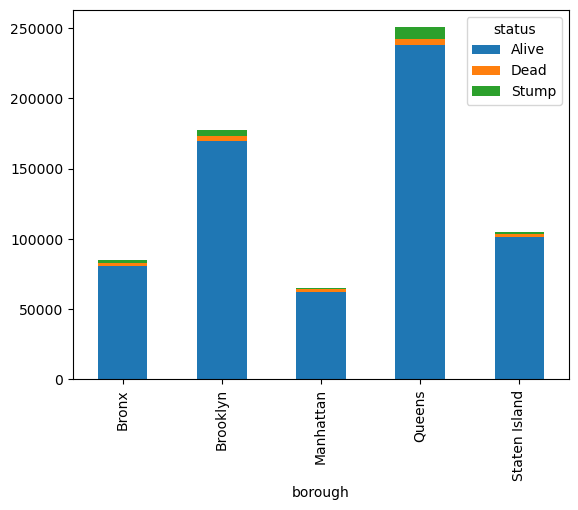

In [6]:
good_maple = trees[(trees["health"] == "Good") & (trees["spc_common"] == "red maple")]

trees.groupby(["borough", "status"]).size().unstack().plot(kind='bar', stacked=True)


<Axes: xlabel='borough,status'>

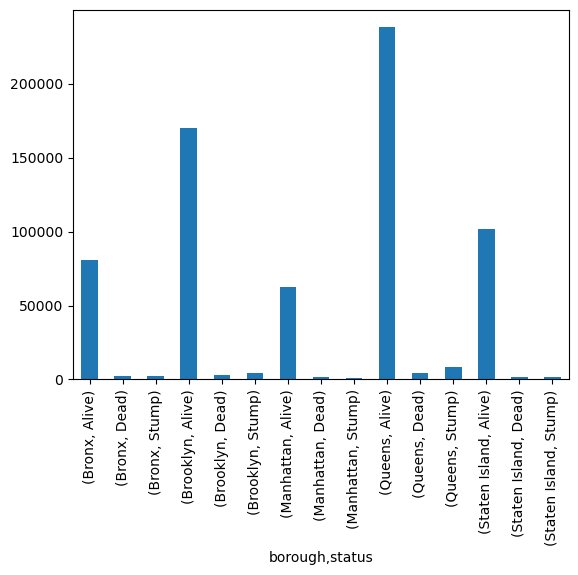

In [7]:
trees.groupby(["borough", "status"]).size().plot(kind='bar', stacked=True)

In [8]:
trees.columns

Index(['block_id', 'created_at', 'tree_dbh', 'stump_diam', 'curb_loc',
       'status', 'health', 'spc_latin', 'spc_common', 'steward', 'guards',
       'sidewalk', 'user_type', 'problems', 'root_stone', 'root_grate',
       'root_other', 'trunk_wire', 'trnk_light', 'trnk_other', 'brch_light',
       'brch_shoe', 'brch_other', 'address', 'postcode', 'zip_city',
       'community board', 'borocode', 'borough', 'cncldist', 'st_assem',
       'st_senate', 'nta', 'nta_name', 'boro_ct', 'state', 'latitude',
       'longitude', 'x_sp', 'y_sp', 'council district', 'census tract', 'bin',
       'bbl'],
      dtype='object')

In [9]:
trees.loc[180683]

block_id                       348711
created_at                 08/27/2015
tree_dbh                            3
stump_diam                          0
curb_loc                       OnCurb
status                          Alive
health                           Fair
spc_latin                 Acer rubrum
spc_common                  red maple
steward                           NaN
guards                            NaN
sidewalk                     NoDamage
user_type            TreesCount Staff
problems                          NaN
root_stone                         No
root_grate                         No
root_other                         No
trunk_wire                         No
trnk_light                         No
trnk_other                         No
brch_light                         No
brch_shoe                          No
brch_other                         No
address             108-005 70 AVENUE
postcode                        11375
zip_city                 Forest Hills
community bo

In [10]:
healthy_t = trees[["health","borough", "spc_common"]]
healthy_t

,health,borough,spc_common
tree_id,,,
180683,Fair,Queens,red maple
200540,Fair,Queens,pin oak
204026,Good,Brooklyn,honeylocust
204337,Good,Brooklyn,honeylocust
189565,Good,Brooklyn,American linden
...,...,...,...
155433,Good,Brooklyn,pin oak
183795,Good,Queens,Kentucky yellowwood
166161,Good,Staten Island,red maple


In [11]:
trees[trees.status !="Alive"][["status", "health"]]

,status,health
tree_id,,
211205,Stump,NaN
187807,Dead,NaN
208322,Dead,NaN
209058,Dead,NaN
203597,Stump,NaN
...,...,...
156162,Dead,NaN
170888,Stump,NaN
177922,Stump,NaN


In [12]:
trees.columns

Index(['block_id', 'created_at', 'tree_dbh', 'stump_diam', 'curb_loc',
       'status', 'health', 'spc_latin', 'spc_common', 'steward', 'guards',
       'sidewalk', 'user_type', 'problems', 'root_stone', 'root_grate',
       'root_other', 'trunk_wire', 'trnk_light', 'trnk_other', 'brch_light',
       'brch_shoe', 'brch_other', 'address', 'postcode', 'zip_city',
       'community board', 'borocode', 'borough', 'cncldist', 'st_assem',
       'st_senate', 'nta', 'nta_name', 'boro_ct', 'state', 'latitude',
       'longitude', 'x_sp', 'y_sp', 'council district', 'census tract', 'bin',
       'bbl'],
      dtype='object')

In [13]:
trees.loc[170888]

block_id                         231931
created_at                   08/24/2015
tree_dbh                              0
stump_diam                            5
curb_loc                         OnCurb
status                            Stump
health                              NaN
spc_latin                           NaN
spc_common                          NaN
steward                             NaN
guards                              NaN
sidewalk                            NaN
user_type              TreesCount Staff
problems                            NaN
root_stone                           No
root_grate                           No
root_other                           No
trunk_wire                           No
trnk_light                           No
trnk_other                           No
brch_light                           No
brch_shoe                            No
brch_other                           No
address             2327 BEDFORD AVENUE
postcode                          11226


In [14]:
trees.status[trees.status !="Alive"].value_counts()

trees[trees.status !="Alive"][["status"]].value_counts()

status
Stump     17654
Dead      13961
Name: count, dtype: int64

In [15]:
trees[["status", "health"]].sort_values(by=["status", "health"])

,status,health
tree_id,,
180683,Alive,Fair
200540,Alive,Fair
192755,Alive,Fair
195202,Alive,Fair
192998,Alive,Fair
...,...,...
152836,Stump,NaN
191219,Stump,NaN
170888,Stump,NaN


In [16]:
def from_celsius(temp):
    return temp*9/5 + 32

df = pd.DataFrame([list(range(0,100,10)), list(range(5,105, 10))])

from_celsius(df)


,0,1,2,3,4,5,6,7,8,9
0,32.0,50.0,68.0,86.0,104.0,122.0,140.0,158.0,176.0,194.0
1,41.0,59.0,77.0,95.0,113.0,131.0,149.0,167.0,185.0,203.0


In [17]:
trees.groupby(["health", "borough"])[["tree_dbh"]].mean()

tree_dbh
health borough                 
Fair   Bronx           9.211812
       Brooklyn       11.286085
       Manhattan       8.086562
       Queens         12.617905
       Staten Island  10.234125
Good   Bronx          10.341261
       Brooklyn       12.485993
       Manhattan       9.061067
       Queens         13.299946
       Staten Island  11.005758
Poor   Bronx           7.598384
       Brooklyn        8.709398
       Manhattan       6.816847
       Queens         10.722735
       Staten Island   8.707173

In [18]:
trees.groupby(["borough", "status"]).size().unstack()

status,Alive,Dead,Stump
borough,,,
Bronx,80585,2530,2088
Brooklyn,169744,3319,4230
Manhattan,62427,1802,1194
Queens,237974,4440,8137
Staten Island,101443,1870,2005


In [19]:
trees.health[trees.status =="Alive"].value_counts()


health
Good    528850
Fair     96504
Poor     26818
Name: count, dtype: int64

In [20]:
trees.health[(trees.spc_common == "honeylocust") | (trees.spc_common == "Callery pear")].value_counts()


health
Good    102574
Fair     17341
Poor      3279
Name: count, dtype: int64

In [21]:
trees.groupby("borough")[["health"]].value_counts()

borough        health
Bronx          Good       66603
               Fair       10887
               Poor        3095
Brooklyn       Good      138212
               Fair       25073
               Poor        6459
Manhattan      Good       47358
               Fair       11460
               Poor        3609
Queens         Good      194008
               Fair       34549
               Poor        9417
Staten Island  Good       82669
               Fair       14535
               Poor        4238
Name: count, dtype: int64

In [22]:

trees[(trees. borough== "Queens") & 
      ((trees.status == "Dead") | 
       (trees.health == "Poor"))]

,block_id,created_at,tree_dbh,stump_diam,curb_loc,status,health,spc_latin,spc_common,steward,...,boro_ct,state,latitude,longitude,x_sp,y_sp,council district,census tract,bin,bbl
tree_id,,,,,,,,,,,,,,,,,,,,,
203726,302371,09/05/2015,8,0,OnCurb,Alive,Poor,Platanus x acerifolia,London planetree,NaN,...,4010500,New York,40.781735,-73.912020,1008615.374,224096.2740,22.0,105.0,4019059.0,4.008710e+09
161242,339804,08/20/2015,3,0,OnCurb,Alive,Poor,Gleditsia triacanthos var. inermis,honeylocust,NaN,...,4097203,New York,40.596836,-73.772454,1047441.721,156802.1034,31.0,97203.0,4302129.0,4.159550e+09
180516,344567,08/27/2015,9,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,NaN,...,4057700,New York,40.700997,-73.892703,1014000.929,194686.8669,30.0,577.0,4088367.0,4.036380e+09
201817,338314,09/04/2015,2,0,OffsetFromCurb,Alive,Poor,Tilia americana,American linden,NaN,...,4093800,New York,40.583449,-73.824058,1033120.673,151891.6415,32.0,938.0,4533406.0,4.161768e+09
201819,338314,09/04/2015,2,0,OffsetFromCurb,Alive,Poor,Tilia americana,American linden,NaN,...,4093800,New York,40.583503,-73.823871,1033172.504,151911.4853,32.0,938.0,4533404.0,4.161768e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201820,338314,09/04/2015,2,0,OffsetFromCurb,Alive,Poor,Tilia americana,American linden,NaN,...,4093800,New York,40.583523,-73.823804,1033191.182,151918.6365,32.0,938.0,4533787.0,4.161768e+09
180436,344467,08/27/2015,9,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,1or2,...,4057700,New York,40.700948,-73.891922,1014217.396,194669.2098,30.0,577.0,4086899.0,4.035930e+09
195263,343483,09/01/2015,6,0,OnCurb,Alive,Poor,Ginkgo biloba,ginkgo,NaN,...,4026902,New York,40.744420,-73.884180,1016343.381,210510.0416,25.0,26902.0,4037308.0,4.015090e+09


In [23]:
trees.status.where(trees.status != "Alive", trees.health)

tree_id
180683    Fair
200540    Fair
204026    Good
204337    Good
189565    Good
          ... 
155433    Good
183795    Good
166161    Good
184028    Good
200607    Fair
Name: status, Length: 683788, dtype: object

In [24]:
def tree_health_by_boro(trees):
	combined_status = trees.status.where(trees.status != "Alive", trees.health)
	num_per_boro = trees.groupby("borough").size()
	combined_per_boro = trees.groupby(["borough",combined_status]).size()
	pct_per_boro = combined_per_boro/num_per_boro*100.0
	pct_per_boro_df = pct_per_boro.unstack()

	return pct_per_boro_df[["Good", "Fair","Poor", "Dead", "Stump"]]

tree_health_by_boro(trees)


status,Good,Fair,Poor,Dead,Stump
borough,,,,,
Bronx,78.169783,12.777719,3.632501,2.969379,2.450618
Brooklyn,77.956829,14.142126,3.643122,1.872042,2.385881
Manhattan,72.387387,17.516775,5.516409,2.754383,1.825046
Queens,77.432539,13.789209,3.758516,1.772094,3.247642
Staten Island,78.494654,13.801060,4.024003,1.775575,1.903758


In [25]:
df1 = pd.DataFrame([['a', 1], ['b', 2]], columns=['letter', 'number'])
df2 = pd.DataFrame([['a', 1], ['c', 4]], columns=['letter', 'number'])
df3 = pd.DataFrame([['b', 1], ['d', 2]], columns=['entry', 'number'])


In [26]:
df1

,letter,number
0,a,1
1,b,2


In [27]:
df2

,letter,number
0,a,1
1,c,4


In [28]:
df3

,entry,number
0,b,1
1,d,2


In [29]:
#df1.join(df1,df2, on = "number", how = "outer") 
df1.merge(df2, on = "number", how = "left") 



,letter_x,number,letter_y
0,a,1,a
1,b,2,NaN


In [30]:
trees[["block_id", "status"]]

,block_id,status
tree_id,,
180683,348711,Alive
200540,315986,Alive
204026,218365,Alive
204337,217969,Alive
189565,223043,Alive
...,...,...
155433,217978,Alive
183795,348185,Alive
166161,401670,Alive


In [31]:
filter_col = [col for col in trees_life if col.startswith('lifespan_cat_eq')]

pd.melt(trees_life,value_vars=filter_col,
id_vars= ["Common Name", "Scientific Name"],
var_name='lifespan_cat')


,Common Name,Scientific Name,lifespan_cat,value


# Task: calculate average by common name

In [32]:
trees_life.groupby("Common Name").mean(numeric_only=True)

,Average_lifespan,Maximum_lifespan
Common Name,,
"Ash, Green",120.0,175.0
"Ash, White",260.0,300.0
Basswood,100.0,140.0
"Beech, American",300.0,400.0
"Birch, Gray",50.0,NaN
...,...,...
Sweetgum,200.0,300.0
Tulip–Poplar,250.0,450.0
"Tupelo, Black",250.0,600.0


In [33]:
trees_life.groupby("Common Name").mean(numeric_only=True)




,Average_lifespan,Maximum_lifespan
Common Name,,
"Ash, Green",120.0,175.0
"Ash, White",260.0,300.0
Basswood,100.0,140.0
"Beech, American",300.0,400.0
"Birch, Gray",50.0,NaN
...,...,...
Sweetgum,200.0,300.0
Tulip–Poplar,250.0,450.0
"Tupelo, Black",250.0,600.0


In [34]:
# Maybe think about ways to summarize this data....group by lifespan?

trees_life.groupby("Average_lifespan").value_counts()



Average_lifespan  Common Name           Scientific Name          Maximum_lifespan
60                Locust, Black         Robinia pseudoacacia     100.0               1
                  Persimmon             Diospyros virginiana     80.0                1
70                Willow, Black         Salix nigra              85.0                1
75                Boxelder              Acer negundo             100.0               1
                  Osage-orange          Maclura pomifera         300.0               1
80                Cucumbertree          Magnolia acuminata       250.0               1
                  Magnolia, Southern    Magnolia grandiflora     120.0               1
                  Oak, Scarlet          Quercus coccinea         180.0               1
100               Basswood              Tilia americana          140.0               1
                  Birch, Paper          Betula papyrifera        140.0               1
                  Cherry, Black         Prunus s

In [35]:
trees_life["lifespan_cat"] = pd.cut(trees_life['Average_lifespan'], 
                                    bins=[0, 90, 200, 300, 600], right = True,
                                    labels=['Short', 'Medium', 'Long', 'ExtraLong'])
trees_life["lifespan_cat_split"] = pd.cut(trees_life['Average_lifespan'], 
                                    bins=4,
                                    labels=['Short', 'Medium', 'Long', 'ExtraLong'])
trees_life["lifespan_cat_eq"] = pd.qcut(trees_life['Average_lifespan'], 
                                    q=4,
                                    labels=['Short', 'Medium', 'Long', 'ExtraLong'])


In [36]:
trees_life[["Average_lifespan","lifespan_cat", "lifespan_cat_split","lifespan_cat_eq"]].value_counts() 

Average_lifespan  lifespan_cat  lifespan_cat_split  lifespan_cat_eq
100               Medium        Short               Short              16
200               Medium        Medium              Long                9
300               Long          Medium              ExtraLong           6
150               Medium        Short               Medium              6
250               Long          Medium              ExtraLong           4
80                Short         Short               Short               3
175               Medium        Short               Long                3
75                Short         Short               Short               2
120               Medium        Short               Medium              2
125               Medium        Short               Medium              2
60                Short         Short               Short               2
50                Short         Short               Short               1
450               ExtraLong     Long        

In [37]:
trees_life = pd.get_dummies(trees_life, columns=['lifespan_cat_eq'], dtype=int)
trees_life


,Common Name,Scientific Name,Average_lifespan,Maximum_lifespan,lifespan_cat,lifespan_cat_split,lifespan_cat_eq_Short,lifespan_cat_eq_Medium,lifespan_cat_eq_Long,lifespan_cat_eq_ExtraLong
0,"Ash, Green",Fraxinus pennsylvanicum,120,175.0,Medium,Short,0,1,0,0
1,"Ash, White",Fraxinus americana,260,300.0,Long,Medium,0,0,0,1
2,Basswood,Tilia americana,100,140.0,Medium,Short,1,0,0,0
3,"Beech, American",Fagus grandifolia,300,400.0,Long,Medium,0,0,0,1
4,"Birch, Gray",Betula populifolia,50,NaN,Short,Short,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
56,"Spruce, Blue",Picea pungens,150,350.0,Medium,Short,0,1,0,0
57,Sweetgum,Liquidambar styraciflua,200,300.0,Medium,Medium,0,0,1,0
58,"Tupelo, Black",Nyssa sylvatica,250,600.0,Long,Medium,0,0,0,1
59,"Walnut, Black",Juglans nigra,150,250.0,Medium,Short,0,1,0,0


In [38]:
trees_life.pivot(index='Common Name', 
                 columns='lifespan_cat', values='Average_lifespan')


lifespan_cat,Short,Medium,Long,ExtraLong
Common Name,,,,
"Ash, Green",NaN,120.0,NaN,NaN
"Ash, White",NaN,NaN,260.0,NaN
Basswood,NaN,100.0,NaN,NaN
"Beech, American",NaN,NaN,300.0,NaN
"Birch, Gray",50.0,NaN,NaN,NaN
...,...,...,...,...
Sweetgum,NaN,200.0,NaN,NaN
Tulip–Poplar,NaN,NaN,250.0,NaN
"Tupelo, Black",NaN,NaN,250.0,NaN


In [39]:
filter_col = [col for col in trees_life if col.startswith('lifespan_cat_eq')]
filter_col.insert(0, "Common Name")
trees_life[filter_col]

,Common Name,lifespan_cat_eq_Short,lifespan_cat_eq_Medium,lifespan_cat_eq_Long,lifespan_cat_eq_ExtraLong
0,"Ash, Green",0,1,0,0
1,"Ash, White",0,0,0,1
2,Basswood,1,0,0,0
3,"Beech, American",0,0,0,1
4,"Birch, Gray",1,0,0,0
...,...,...,...,...,...
56,"Spruce, Blue",0,1,0,0
57,Sweetgum,0,0,1,0
58,"Tupelo, Black",0,0,0,1
59,"Walnut, Black",0,1,0,0


### melting: reshaping datasets

In [40]:
trees_cat = trees_life.melt(value_vars=filter_col,
                id_vars= ["Common Name"],
                var_name='lifespan_cat').sort_values(by = "Common Name")
trees_cat

,Common Name,lifespan_cat,value
0,"Ash, Green",lifespan_cat_eq_Short,0
61,"Ash, Green",lifespan_cat_eq_Medium,1
183,"Ash, Green",lifespan_cat_eq_ExtraLong,0
122,"Ash, Green",lifespan_cat_eq_Long,0
184,"Ash, White",lifespan_cat_eq_ExtraLong,1
...,...,...,...
181,"Walnut, Black",lifespan_cat_eq_Long,0
121,"Willow, Black",lifespan_cat_eq_Medium,0
60,"Willow, Black",lifespan_cat_eq_Short,1
182,"Willow, Black",lifespan_cat_eq_Long,0


In [41]:
pd.pivot(trees_life, index=["Common Name"],
         columns = "lifespan_cat_split", values = "lifespan_cat_split" ) 
#trees_life.columns

lifespan_cat_split,Short,Medium,Long,ExtraLong
Common Name,,,,
"Ash, Green",Short,NaN,NaN,NaN
"Ash, White",NaN,Medium,NaN,NaN
Basswood,Short,NaN,NaN,NaN
"Beech, American",NaN,Medium,NaN,NaN
"Birch, Gray",Short,NaN,NaN,NaN
...,...,...,...,...
Sweetgum,NaN,Medium,NaN,NaN
Tulip–Poplar,NaN,Medium,NaN,NaN
"Tupelo, Black",NaN,Medium,NaN,NaN


In [42]:
filter_col = [col for col in trees_life if col.startswith('lifespan_cat_eq')]

stub = pd.melt(trees_life,value_vars=filter_col,
id_vars= ["Common Name", "Scientific Name"],
var_name='lifespan_cat')

pd.wide_to_long(trees_life, stubnames="lifespan_cat_eq", 
i="Common Name", 
j="lifespan_cat", suffix='\\w+')

trees_life.pivot(index='Common Name', columns='lifespan_cat', values='Average_lifespan')

pd.get_dummies(stub, columns=['lifespan_cat'], dtype=int)

,Common Name,Scientific Name,value,lifespan_cat_lifespan_cat_eq_ExtraLong,lifespan_cat_lifespan_cat_eq_Long,lifespan_cat_lifespan_cat_eq_Medium,lifespan_cat_lifespan_cat_eq_Short
0,"Ash, Green",Fraxinus pennsylvanicum,0,0,0,0,1
1,"Ash, White",Fraxinus americana,0,0,0,0,1
2,Basswood,Tilia americana,1,0,0,0,1
3,"Beech, American",Fagus grandifolia,0,0,0,0,1
4,"Birch, Gray",Betula populifolia,1,0,0,0,1
...,...,...,...,...,...,...,...
239,"Spruce, Blue",Picea pungens,0,1,0,0,0
240,Sweetgum,Liquidambar styraciflua,0,1,0,0,0
241,"Tupelo, Black",Nyssa sylvatica,1,1,0,0,0
242,"Walnut, Black",Juglans nigra,0,1,0,0,0


## Where

In [89]:
cond = trees_life['Average_lifespan'] > 150
trees_life["lifespan_short"] = trees_life['Average_lifespan'].where(cond, other = "short lived")
trees_life["lifespan_short"].value_counts()


lifespan_short
short lived    36
200             9
300             6
250             4
175             3
260             1
600             1
450             1
Name: count, dtype: int64

In [77]:
cond = trees_life['Average_lifespan'] > 150
trees_life["lifespan_short"] = trees_life['Average_lifespan'].where(cond, other = "short lived")
trees_life["lifespan_short"].value_counts()

lifespan_short
short lived    36
200             9
300             6
250             4
175             3
260             1
600             1
450             1
Name: count, dtype: int64

## CUTTING

In [48]:
#Cut the range into equal slices:
trees_life["lifespan_cat_split"] = pd.cut(trees_life['Average_lifespan'], 
bins=4,
labels=['Short', 'Medium', 'Long', 'ExtraLong'])


trees_life["lifespan_cat_split"].value_counts()

lifespan_cat_split
Short        39
Medium       20
Long          1
ExtraLong     1
Name: count, dtype: int64

In [53]:
#Cut the distribution into equal slices:

trees_life["lifespan_cat_eq"] = pd.qcut(trees_life['Average_lifespan'], 
q=4,
labels=['Short', 'Medium', 'Long', 'ExtraLong'])

trees_life["lifespan_cat_eq"].value_counts()

lifespan_cat_eq
Short        25
ExtraLong    13
Long         12
Medium       11
Name: count, dtype: int64

In [49]:
#DIY where you set the cut points: 
trees_life["lifespan_cat"] = pd.cut(trees_life['Average_lifespan'], 
bins=[0, 90, 200, 300, 600], right = True,
labels=['Short', 'Medium', 'Long', 'ExtraLong'])

trees_life["lifespan_cat"].value_counts()

lifespan_cat
Medium       39
Long         11
Short         9
ExtraLong     2
Name: count, dtype: int64

## Pivoting

In [97]:
filter_col = [col for col in trees_life if col.startswith('lifespan_cat_eq')]

pd.melt(trees_life,value_vars=filter_col,
id_vars= ["Common Name", "Scientific Name"],
var_name='lifespan_cat')

trees_life.pivot(index='Common Name', columns='lifespan_cat', 
                 values='Average_lifespan')

pd.get_dummies(trees_life, columns=['lifespan_cat'], dtype=int)


,Common Name,Scientific Name,Average_lifespan,Maximum_lifespan,lifespan_cat_split,lifespan_cat_eq_Short,lifespan_cat_eq_Medium,lifespan_cat_eq_Long,lifespan_cat_eq_ExtraLong,lifespan_cat_eq,lifespan_Long,lifespan_short,lifespan_cat_Short,lifespan_cat_Medium,lifespan_cat_Long,lifespan_cat_ExtraLong
0,"Ash, Green",Fraxinus pennsylvanicum,120,175.0,Short,0,1,0,0,Medium,120,short lived,0,1,0,0
1,"Ash, White",Fraxinus americana,260,300.0,Medium,0,0,0,1,ExtraLong,260,260,0,0,1,0
2,Basswood,Tilia americana,100,140.0,Short,1,0,0,0,Short,100,short lived,0,1,0,0
3,"Beech, American",Fagus grandifolia,300,400.0,Medium,0,0,0,1,ExtraLong,300,300,0,0,1,0
4,"Birch, Gray",Betula populifolia,50,NaN,Short,1,0,0,0,Short,short lived,short lived,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,"Spruce, Blue",Picea pungens,150,350.0,Short,0,1,0,0,Medium,150,short lived,0,1,0,0
57,Sweetgum,Liquidambar styraciflua,200,300.0,Medium,0,0,1,0,Long,200,200,0,1,0,0
58,"Tupelo, Black",Nyssa sylvatica,250,600.0,Medium,0,0,0,1,ExtraLong,250,250,0,0,1,0
59,"Walnut, Black",Juglans nigra,150,250.0,Short,0,1,0,0,Medium,150,short lived,0,1,0,0


## MERGING

In [99]:
df1 = pd.DataFrame([['a', 1], ['b', 2]], columns=['letter', 'number'])
df2 = pd.DataFrame([['a', 1], ['c', 4]], columns=['letter', 'number'])
df3 = pd.DataFrame([['b', 1], ['d', 2]], columns=['entry', 'number'])

print(df1)
print(df2)
print(df3)




  letter  number
0      a       1
1      b       2
  letter  number
0      a       1
1      c       4
  entry  number
0     b       1
1     d       2


In [100]:
pd.concat([df1,df2])


,letter,number
0,a,1
1,b,2
0,a,1
1,c,4


In [101]:
pd.concat([df1,df3])



,letter,number,entry
0,a,1,NaN
1,b,2,NaN
0,NaN,1,b
1,NaN,2,d


In [115]:
df1.merge(df2, on = "number", how = "left")#.set_index("number")


,letter_x,number,letter_y
0,a,1,a
1,b,2,NaN


In [106]:
df3.set_index("number").join(df1.set_index("number"))

,entry,letter
number,,
1,b,a
2,d,b


In [109]:

pd.merge(df1,df2, on = "entry") ## Play around with this and ‘how’ options

KeyError: 'entry'

In [ ]:
trees_life.groupby("lifespan_cat").value_counts()

/var/folders/g1/9qqnjd1x21dbm_sdrj7lhrlw0000gn/T/ipykernel_75961/1104685712.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  trees_life.groupby("lifespan_cat").value_counts()


lifespan_cat  Common Name         Scientific Name       Average_lifespan  Maximum_lifespan  lifespan_cat_split  lifespan_cat_eq_Short  lifespan_cat_eq_Medium  lifespan_cat_eq_Long  lifespan_cat_eq_ExtraLong
Short         Boxelder            Acer negundo          75                100.0             Short               1                      0                       0                     0                            1
              Cucumbertree        Magnolia acuminata    80                250.0             Short               1                      0                       0                     0                            1
              Locust, Black       Robinia pseudoacacia  60                100.0             Short               1                      0                       0                     0                            1
              Magnolia, Southern  Magnolia grandiflora  80                120.0             Short               1                      0                     

# NOW TIME TO PARTY: Merging

In [ ]:
trees.columns#melt(value_vars=filter_col, id_vars= ["Common Name"], var_name='lifespan_cat')#.sort_values(by = "Common Name").groupby("lifespan_cat").value_counts()



Index(['block_id', 'created_at', 'tree_dbh', 'stump_diam', 'curb_loc',
       'status', 'health', 'spc_latin', 'spc_common', 'steward', 'guards',
       'sidewalk', 'user_type', 'problems', 'root_stone', 'root_grate',
       'root_other', 'trunk_wire', 'trnk_light', 'trnk_other', 'brch_light',
       'brch_shoe', 'brch_other', 'address', 'postcode', 'zip_city',
       'community board', 'borocode', 'borough', 'cncldist', 'st_assem',
       'st_senate', 'nta', 'nta_name', 'boro_ct', 'state', 'latitude',
       'longitude', 'x_sp', 'y_sp', 'council district', 'census tract', 'bin',
       'bbl'],
      dtype='object')

In [ ]:
def tree_health_by_boro(trees):
	combined_status = trees.status.where(trees.status != "Alive", trees.health)
	num_per_boro = trees.groupby("borough").size()
	combined_per_boro = trees.groupby(["borough",combined_status]).size()
	pct_per_boro = combined_per_boro/num_per_boro*100.0
	pct_per_boro_df = pct_per_boro.unstack()

	return pct_per_boro_df[["Good", "Fair", "Poor", "Dead", "Stump"]]

tree_health_by_boro(trees)


status,Good,Fair,Poor,Dead,Stump
borough,,,,,
Bronx,78.169783,12.777719,3.632501,2.969379,2.450618
Brooklyn,77.956829,14.142126,3.643122,1.872042,2.385881
Manhattan,72.387387,17.516775,5.516409,2.754383,1.825046
Queens,77.432539,13.789209,3.758516,1.772094,3.247642
Staten Island,78.494654,13.801060,4.024003,1.775575,1.903758


In [ ]:
pd.melt(trees_life,value_vars=filter_col, id_vars= ["Common Name", "Scientific Name"],var_name='lifespan_cat')


,Common Name,Scientific Name,lifespan_cat,value
0,"Ash, Green",Fraxinus pennsylvanicum,lifespan_cat_eq_Short,0
1,"Ash, White",Fraxinus americana,lifespan_cat_eq_Short,0
2,Basswood,Tilia americana,lifespan_cat_eq_Short,1
3,"Beech, American",Fagus grandifolia,lifespan_cat_eq_Short,0
4,"Birch, Gray",Betula populifolia,lifespan_cat_eq_Short,1
...,...,...,...,...
239,"Spruce, Blue",Picea pungens,lifespan_cat_eq_ExtraLong,0
240,Sweetgum,Liquidambar styraciflua,lifespan_cat_eq_ExtraLong,0
241,"Tupelo, Black",Nyssa sylvatica,lifespan_cat_eq_ExtraLong,1
242,"Walnut, Black",Juglans nigra,lifespan_cat_eq_ExtraLong,0


In [ ]:
trees_life.columns


Index(['Common Name', 'Scientific Name', 'Average_lifespan',
       'Maximum_lifespan', 'lifespan_cat', 'lifespan_cat_split',
       'lifespan_cat_eq_Short', 'lifespan_cat_eq_Medium',
       'lifespan_cat_eq_Long', 'lifespan_cat_eq_ExtraLong'],
      dtype='object')

## Examples: Merging

In [ ]:
trees_merged = trees.merge(trees_life, left_on="spc_latin", 
                        right_on="Scientific Name", how = "outer", indicator = True)
trees_merged.columns
#trees_merged.shape

trees_merged["_merge"].value_counts()


_merge
left_only     552025
both          131763
right_only        28
Name: count, dtype: int64

## Merge checks

In [ ]:
unmatched_left = trees_merged[trees_merged['_merge'] == 'left_only']
unmatched_right = trees_merged[trees_merged['_merge'] == 'right_only']

print("Unmatched in left:")
unmatched_left.spc_common.value_counts()


Unmatched in left:


spc_common
London planetree     87014
honeylocust          64264
Callery pear         58931
Norway maple         34189
littleleaf linden    29742
                     ...  
European alder          47
American larch          46
black pine              37
pitch pine              33
Scots pine              25
Name: count, Length: 99, dtype: int64

In [ ]:

print("\nUnmatched in right:")
unmatched_right["Common Name"].value_counts()


Unmatched in right:


Common Name
Maple, Silver           1
Birch, Yellow           1
Willow, Black           1
Oak, Live               1
Oak, Post               1
Oak, Chestnut           1
Oak, Water              1
Oak, Basket             1
Oak, Blackjack          1
Oak, Overcup            1
Poplar, Balsam          1
Pine, Loblolly          1
Pine, Table Mountain    1
Pine, Shortleaf         1
Mulberry, Red           1
Holly, American         1
Honeylocust             1
Ash, Green              1
Persimmon               1
Catalpa                 1
Chestnut, American      1
Hickory, Mockernut      1
Hickory, Shagbark       1
Pecan                   1
Hickory, Bitternut      1
Birch, Gray             1
Birch, Sweet            1
Elm, Slippery           1
Name: count, dtype: int64

In [ ]:

trees_merged[["spc_latin", "Scientific Name", "spc_common"] ]



,spc_latin,Scientific Name,spc_common
0,Acer,NaN,maple
1,Acer,NaN,maple
2,Acer,NaN,maple
3,Acer,NaN,maple
4,Acer,NaN,maple
...,...,...,...
683811,NaN,NaN,NaN
683812,NaN,NaN,NaN
683813,NaN,NaN,NaN
683814,NaN,NaN,NaN


In [ ]:
trees_merged.spc_latin.value_counts()




spc_latin
Platanus x acerifolia                 87014
Gleditsia triacanthos var. inermis    64264
Pyrus calleryana                      58931
Quercus palustris                     53185
Acer platanoides                      34189
                                      ...  
Pinus nigra                              37
Pinus rigida                             33
Maclura pomifera                         29
Pinus sylvestris                         25
Pinus virginiana                         10
Name: count, Length: 132, dtype: int64

In [ ]:
trees.join(trees_life, how = "left")[["spc_latin", "Scientific Name", "spc_common"]]

,spc_latin,Scientific Name,spc_common
tree_id,,,
180683,Acer rubrum,NaN,red maple
200540,Quercus palustris,NaN,pin oak
204026,Gleditsia triacanthos var. inermis,NaN,honeylocust
204337,Gleditsia triacanthos var. inermis,NaN,honeylocust
189565,Tilia americana,NaN,American linden
...,...,...,...
155433,Quercus palustris,NaN,pin oak
183795,Cladrastis kentukea,NaN,Kentucky yellowwood
166161,Acer rubrum,NaN,red maple


In [ ]:
trees.shape
trees_merged.shape

(683816, 55)

In [ ]:
def tree_health_by_boro(trees):
	combined_status = trees.status.where(trees.status != "Alive", trees.health)
	num_per_boro = trees.groupby("borough").size()
	combined_per_boro = trees.groupby(["borough",combined_status]).size()
	pct_per_boro = combined_per_boro/num_per_boro*100.0
	pct_per_boro_df = pct_per_boro.unstack()

	return pct_per_boro_df[["Good", "Fair", "Poor", "Dead", "Stump"]]

tree_health_by_boro(trees)


status,Good,Fair,Poor,Dead,Stump
borough,,,,,
Bronx,78.169783,12.777719,3.632501,2.969379,2.450618
Brooklyn,77.956829,14.142126,3.643122,1.872042,2.385881
Manhattan,72.387387,17.516775,5.516409,2.754383,1.825046
Queens,77.432539,13.789209,3.758516,1.772094,3.247642
Staten Island,78.494654,13.801060,4.024003,1.775575,1.903758


<Axes: xlabel='borough'>

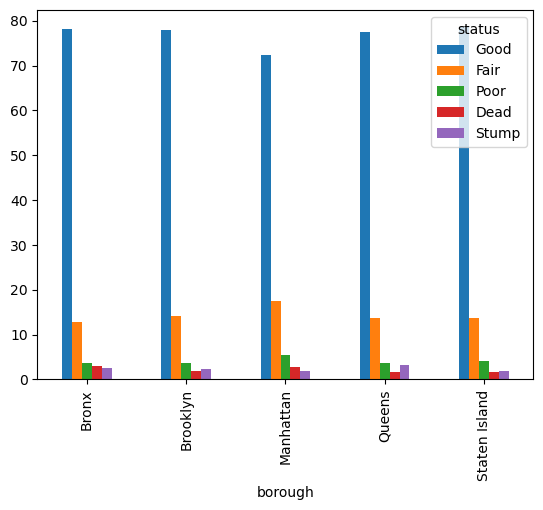

In [ ]:
# PLOTTING PARTY: Plot

tree_health_by_boro(trees).plot.bar()

<Axes: xlabel='borough'>

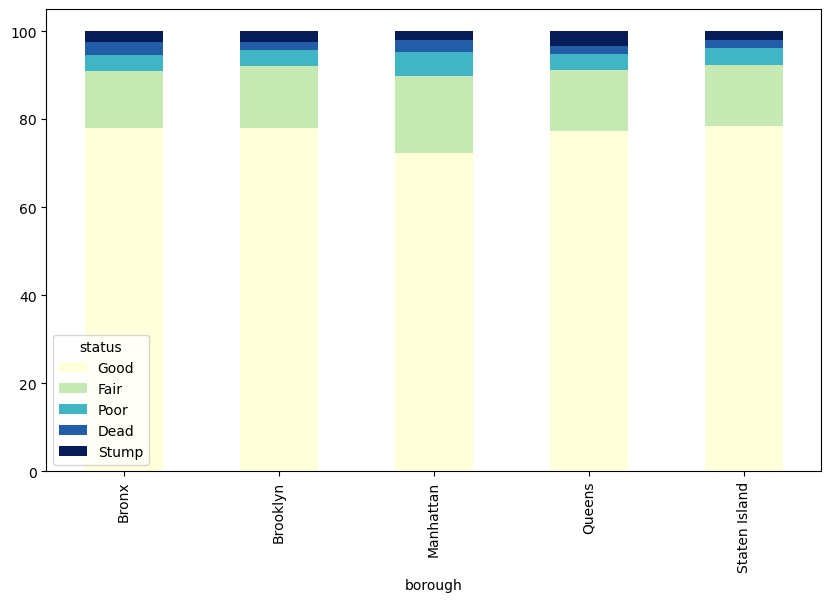

In [ ]:
# stacking
df.plot.bar(stacked=True, figsize=(10, 6), colormap='YlGnBu')

/var/folders/g1/9qqnjd1x21dbm_sdrj7lhrlw0000gn/T/ipykernel_5066/1742274485.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df['borough'])


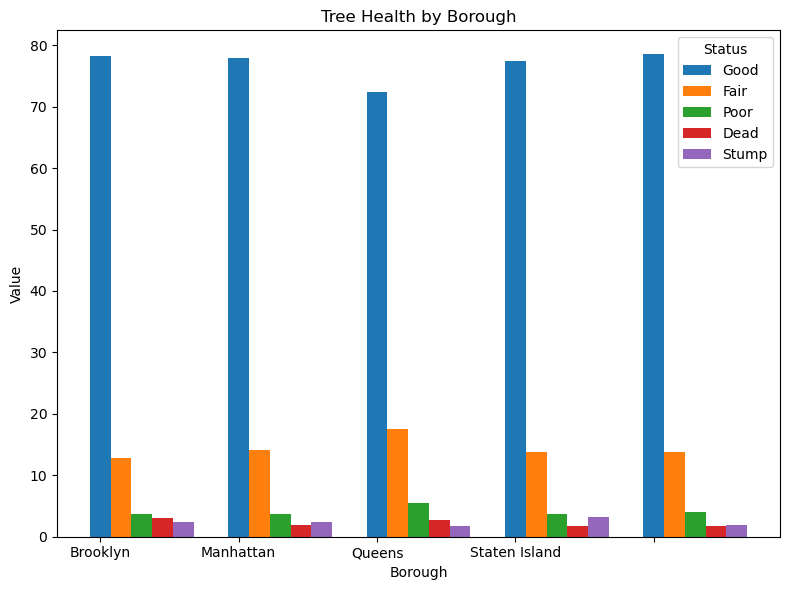

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
df = pd.DataFrame(tree_health_by_boro(trees)).reset_index() 

# Group by borough and status, summing the counts
#df.groupby(['borough', 'status'])['count'].sum().unstack()
df_melted =df.melt(id_vars="borough", var_name="status", value_name="value")
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.15
index = np.arange(len(df['borough']))
# Plot bars for each health status
for i, status in enumerate(df_melted['status'].unique()):
    status_values = df_melted[df_melted['status'] == status]['value']
    ax.bar(index + i * bar_width, status_values, bar_width, label=status)

# Customize plot
ax.set_xticklabels(df['borough'])
ax.set_xlabel('Borough')
ax.set_ylabel('Value')
ax.set_title('Tree Health by Borough')
ax.legend(title="Status")

# Show plot
plt.tight_layout()
plt.show()



<Axes: xlabel='borough', ylabel='value'>

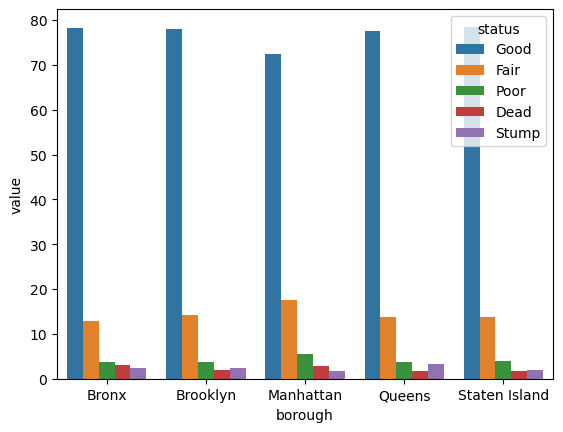

In [ ]:
# Seaborn
df2 = df.reset_index()
df2 = df2.melt(id_vars = "borough")
sns.barplot(df2, x = "borough", y = "value" , hue = "status")

In [ ]:
df = pd.DataFrame(tree_health_by_boro(trees))

#df_melted = df.melt(id_vars="borough", var_name="status", value_name="value")

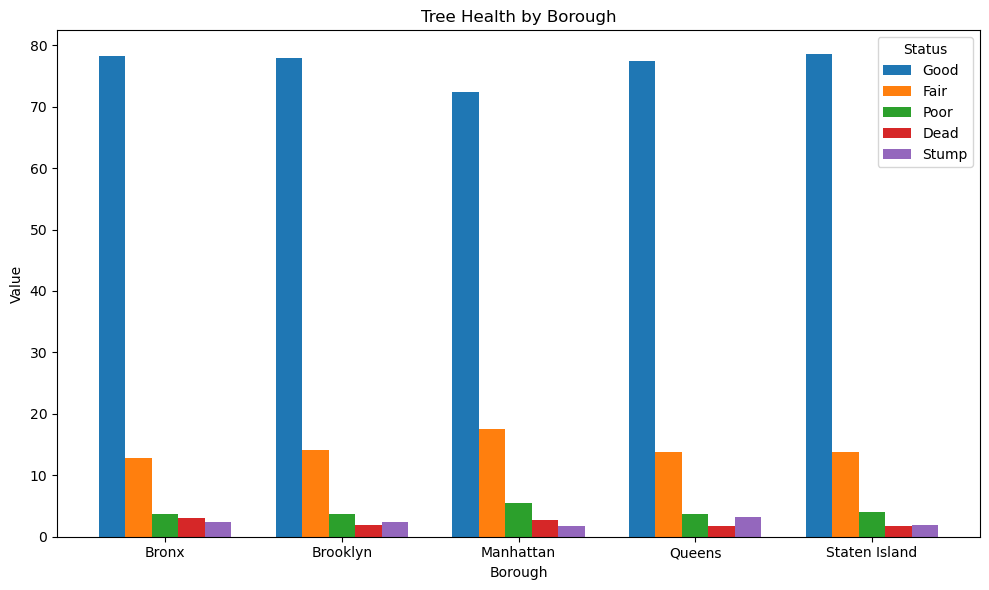

In [ ]:
# matplotlib plotting
#https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(tree_health_by_boro(trees))
df.index

# Melt DataFrame
df = df.reset_index().rename(columns={'index': 'borough'})
df2 = df.melt(id_vars="borough", var_name="status", value_name="value")

# Plot using Matplotlib
fig, ax = plt.subplots(figsize=(10, 6))
statuses = df2['status'].unique()

# Bar width and positioning
bar_width = 0.15
index = np.arange(len(df2['borough'].unique()))

# Plot bars for each status
for i, status in enumerate(statuses):
    ax.bar(index + i * bar_width, df2[df2['status'] == status]['value'], bar_width, label=status)

# Customize plot
ax.set_xticks(index + bar_width * (len(statuses) - 1) / 2)
ax.set_xticklabels(df2['borough'].unique())
ax.set_xlabel('Borough')
ax.set_ylabel('Value')
ax.set_title('Tree Health by Borough')
ax.legend(title="Status")

plt.tight_layout()
plt.show()


In [ ]:
print(df.columns)
print(df.head())

Index(['Good', 'Fair', 'Poor', 'Dead', 'Stump'], dtype='object', name='status')
status              Good       Fair      Poor      Dead     Stump
borough                                                          
Bronx          78.169783  12.777719  3.632501  2.969379  2.450618
Brooklyn       77.956829  14.142126  3.643122  1.872042  2.385881
Manhattan      72.387387  17.516775  5.516409  2.754383  1.825046
Queens         77.432539  13.789209  3.758516  1.772094  3.247642
Staten Island  78.494654  13.801060  4.024003  1.775575  1.903758
